# Is the e-fold budget a good predictor? An out-of-sample check

**The claim being tested.** Section 5 of `lambda_growth_rate_check.ipynb` found that the initial growth rate $\lambda_0$ does not sort the runs into steady oscillation and stall, but that an e-fold budget does: the number of e-folds a small oscillation can gain before the drifting mean pressure takes the drive away, against the number the kick needs to reach the steady amplitude. In closed form (section 5.1 there, section 9 of the notes),

$$B = \frac{\gamma_E V_{pass}}{2\gamma V_{cv}} \ln\frac{\dot m_{net}(\bar P_1)}{\dot m_{net}(P_0)} - \frac{b}{2m} t_1, \qquad \text{steady if } B \gt \ln\frac{\delta_\infty}{\delta_0}$$

That finding came from the same 37 sweep runs the idea was built on, and it used the steady amplitude of those runs ($\delta_\infty = 0.295$ bar) as the target. This notebook tests the criterion on settings it has never seen, with every input computed without simulating the oscillation.

**The predictors.** Four verdicts are compared with the outcome of the full simulation (steady oscillation or stall):

1. $\lambda_{lin}(P_0) \gt 0$ — the naive criterion, "the kick grows at the start".
2. The budget with $\delta_\infty$ fixed at 0.295 bar — the version used in the earlier notebook.
3. The budget with $\delta_\infty$ from the fixed point of the slow equations — the amplitude at which the mass balance $\dot m_{0,in} = \dot m_{0,out}$, the pressure balance and $\lambda(\bar P, \delta) = 0$ hold together, found by a root search from a handful of starting guesses (no time integration). Only a fixed point that is stable (all eigenvalues of the slow Jacobian negative) and live (a mean flow of at least 1 percent of $\dot m_{max}$ through the valves, which rejects the dead equilibria at the edges of the pressure range where both reeds pass nothing) counts as a steady oscillation; when none exists the verdict is stall. This is the criterion proper: everything in it is algebra plus one quadrature for the drift time $t_1$.
4. The three slow ODEs integrated in time — the reference, everything the slow equations know.

**The test sets.** (A) 60 settings with all seven parameters drawn at random at once: valve capacity, reed factor $\zeta$, damping, passive volume, piston mass, kick and inlet pressure, log-uniform over a box around the baseline (0.3 to 3 g/s, 0.45 to 1.0, 0.002 to 0.03 N s/m, 0.7 to 6 times $10^{-4}$ m$^3$, 0.7 to 4 g, 1 to 12 m/s, 5.9 to 6.3 bar). None of these settings appears in the earlier sweeps. (B) An 8 by 8 grid in the plane of passive volume and kick, where the criterion predicts a boundary curve in closed form, $v_0^* = (\omega_0 A / k_{cv}) \delta_\infty e^{-B}$, that can be drawn over the simulated outcomes.

The full simulation is run only until its outcome is settled (the half swing flat to 1 percent for half a second, or fallen to a tenth of its maximum, or the piston at rest), which takes 0.5 to 2 s of simulated time per setting.

**Reading in advance.** Over the 124 new settings the budget gets the outcome right in 117 (55 of the 60 random settings, 62 of the 64 grid points), against 72 for the sign of the initial growth rate and 121 for the three slow ODEs integrated in time. Its misses are one-sided and identifiable: five false stalls among the random settings — four within half an e-fold of the line, all with a reed shut or within a few percent of shutting at the mean pressure, where the finite swing of the kick supplies drive that the small-signal window does not count (the mild form of the $\zeta = 1.2$ case), and one where the slow equations have no stable fixed point although the full model sustains — plus two grid points right at the predicted curve (margins $-0.11$ and $+0.27$ e-folds). Every setting within 0.1 e-folds of the line was called right. One lesson from building the check: a naive fixed-point search picks up dead equilibria at the edges of the pressure range (both reeds passing nothing) and produced six confident false steady verdicts; the stability and liveness tests in predictor 3 remove them.

Runtime: about 6 minutes.

In [1]:
import numpy as np, time
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy.signal import find_peaks

BLUE, ORANGE, AQUA, INK, INK2, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e8e7e3'
BASE = dict(gamma=1.41, R=287.0, cp=1050.0, cv=744.0, P_in=6e5, P_out=5.45e5, P0=5.75e5, T_in=300.0,
            A_neck=2.85e-4, m_gas=0.0015, b_gas=0.005, zeta=0.6, m_max=0.001, x0=0.0, v0=5.0, V0_pass=2e-4, V0_cv=1e-4)


class Model:
    """The full model (valves, gas piston, passive volume), the slow (averaged) model, and the growth rate."""

    def __init__(self, **kw):
        p = dict(BASE); p.update(kw)
        for k, v in p.items():
            setattr(self, k, v)
        self.T0 = self.T_in; self.dP_max = (self.P_in - self.P_out) / (2 * self.zeta)
        self.gamma_E = 1.0 + self.R / self.cv; self.Cf = self.cp * self.R / self.cv
        self.PSI = np.linspace(0, 2 * np.pi, 513)[:-1]; self.CPS = np.cos(self.PSI)

    def reed_vec(self, dP):
        dP = np.asarray(dP, dtype=float); u = dP / self.dP_max; out = np.zeros_like(dP)
        mo = (dP > 0) & (dP < self.dP_max); mr = dP <= 0
        out[mo] = self.m_max * (1 - u[mo]) * np.sqrt(u[mo]); out[mr] = -self.m_max * (1 - u[mr]) * np.sqrt(np.abs(u[mr]))
        return out

    def reed(self, dP):
        return float(self.reed_vec(np.array([dP]))[0])

    # ---------- full model ----------
    def full_ode(self, t, y):
        x, v, M, E = y
        Vc = self.V0_cv + x * self.A_neck; T = E / (self.cv * M); P = M * self.R * T / Vc
        Vp = self.V0_pass - x * self.A_neck; Pp = self.P0 * (self.V0_pass / Vp) ** self.gamma
        mi = self.reed(self.P_in - P); mo = self.reed(P - self.P_out)
        return [v, (P - Pp) * self.A_neck / self.m_gas - (self.b_gas / self.m_gas) * v, mi - mo,
                -P * self.A_neck * v + mi * self.cp * self.T_in - mo * self.cp * T]

    def outcome_full(self, t_max=6.0, fs=10000.0, rtol=1e-7, chunk=0.25):
        """Run the full model until the outcome is settled: 'steady' when the half swing has been flat to 1 percent for
        0.5 s (and exceeds 10 mbar), 'stall' when the swing has fallen below a tenth of its maximum or the piston has stopped.
        Returns the outcome, the time it took to decide, and the per-cycle (t, half swing) trace."""
        M0 = self.P0 * self.V0_cv / (self.R * self.T0)
        y = [self.x0, self.v0, M0, self.cv * M0 * self.T0]
        ts, Ps = [], []; t0 = 0.0; verdict = None
        while t0 < t_max - 1e-9:
            t1 = min(t0 + chunk, t_max)
            te = np.append(np.arange(t0, t1, 1.0 / fs), t1)
            sol = solve_ivp(self.full_ode, (t0, t1), y, t_eval=te, method='RK45', rtol=rtol, atol=1e-10)
            x, v, M, E = sol.y; T = E / (self.cv * M); P = M * self.R * T / (self.V0_cv + x * self.A_neck)
            ts.append(sol.t[:-1]); Ps.append(P[:-1]); y = sol.y[:, -1]; t0 = t1
            tail = sol.t > t1 - 0.05
            if np.abs(v[tail]).max() < 1e-3 and t1 > 0.3:
                verdict = 'stall'; break
            if t1 >= 1.0:
                tm, half = per_cycle(np.concatenate(ts), np.concatenate(Ps))
                if len(tm) > 20:
                    late = tm > t1 - 0.5; h = half[late]
                    if h.mean() > 1e3 and (h.max() - h.min()) < 0.01 * h.mean():
                        verdict = 'steady'; break
                    if half.max() > 500.0 and half[tm > t1 - 0.3].max() < 0.1 * half.max():
                        verdict = 'stall'; break
        t, P = np.concatenate(ts), np.concatenate(Ps); tm, half = per_cycle(t, P)
        if verdict is None:
            verdict = 'steady' if half[tm > t_max - 0.2].mean() > 1e3 else 'stall'
        return verdict, t0, tm, half

    # ---------- slow (averaged) model ----------
    def F0F1(self, dPbar, delta):
        vals = self.reed_vec(dPbar + delta * self.CPS)
        return vals.mean(), 2.0 * (vals * self.CPS).mean()

    def geom(self, Pb):
        Vp = self.V0_pass * (self.P0 / Pb) ** (1.0 / self.gamma); Vc = self.V0_cv + (self.V0_pass - Vp)
        kcv = self.gamma_E * Pb * self.A_neck ** 2 / Vc; kp = self.gamma * Pb * self.A_neck ** 2 / Vp
        return Vp, Vc, kcv, kp, np.sqrt((kcv + kp) / self.m_gas)

    def gains(self, Pb, delta):
        """Mean flows and first-harmonic gains of both valves at (Pbar, delta); tangent slopes below 1 Pa of swing."""
        if delta > 1.0:
            F0i, F1i = self.F0F1(self.P_in - Pb, delta); F0o, F1o = self.F0F1(Pb - self.P_out, delta)
            return F0i, F0o, F1i / delta, F1o / delta
        h = 1.0
        Ni = (self.reed(self.P_in - Pb + h) - self.reed(self.P_in - Pb - h)) / (2 * h)
        No = (self.reed(Pb - self.P_out + h) - self.reed(Pb - self.P_out - h)) / (2 * h)
        return self.reed(self.P_in - Pb), self.reed(Pb - self.P_out), Ni, No

    def lam(self, Pb, Tb, delta):
        """Growth rate (20) with the finite-amplitude gains (17) at the slow state (Pbar, Tbar, delta), piston quasi-static."""
        Vp, Vc, kcv, kp, w = self.geom(Pb)
        F0i, F0o, Ni, No = self.gains(Pb, delta)
        g = -(self.Cf / Vc) * (self.T_in * Ni + Tb * No)
        return -self.b_gas / (2 * self.m_gas) + 0.5 * g * kcv / (kcv + kp), g

    def slow_rhs(self, t, y):
        Mb, Pb, a = y; a = max(a, 0.0)
        Vp, Vc, kcv, kp, w = self.geom(Pb); Tb = Pb * Vc / (Mb * self.R); delta = kcv * a / self.A_neck
        F0i, F0o, Ni, No = self.gains(Pb, delta)
        g = -(self.Cf / Vc) * (self.T_in * Ni + Tb * No)
        lam = -self.b_gas / (2 * self.m_gas) + 0.5 * g * kcv / (kcv + kp)
        dPb = (self.Cf * (self.T_in * F0i - Tb * F0o) - Vc * g * delta ** 2 / (2 * Pb)) / (Vc + (self.gamma_E / self.gamma) * Vp)
        dPp = 1e-4 * max(abs(dPb), 1.0); wdot = (self.geom(Pb + dPp)[4] - w) / dPp * dPb
        da = lam * a - (wdot / (2 * w)) * a
        if a <= 1e-10 and da < 0:
            da = 0.0
        return [F0i - F0o, dPb, da]

    def outcome_avg(self, t_max=6.0, chunk=0.25):
        """The three slow ODEs integrated in time, in chunks, with the same stopping rules as the full run:
        steady once the amplitude has been flat to 1 percent for 0.5 s (and exceeds 10 mbar), stall once it has fallen
        below a tenth of its maximum or below 1 mbar."""
        M0 = self.P0 * self.V0_cv / (self.R * self.T0); w0 = self.geom(self.P0)[4]
        y = [M0, self.P0, self.v0 / w0]; t0 = 0.0; ts, ds = [], []
        while t0 < t_max - 1e-9:
            t1 = min(t0 + chunk, t_max); te = np.linspace(t0, t1, 51)
            sol = solve_ivp(self.slow_rhs, (t0, t1), y, t_eval=te, method='LSODA', rtol=1e-7, atol=[1e-12, 1e-3, 1e-11], max_step=2e-3)
            Mb, Pb, a = sol.y; d = np.array([self.geom(p)[2] for p in Pb]) * np.maximum(a, 0) / self.A_neck
            ts.append(sol.t); ds.append(d); y = sol.y[:, -1]; t0 = t1
            tt, dd = np.concatenate(ts), np.concatenate(ds)
            if dd[-1] < 1e2 and t1 > 0.3:
                return 'stall'
            if dd.max() > 500.0 and dd[tt > t1 - 0.3].max() < 0.1 * dd.max():
                return 'stall'
            if t1 >= 1.0:
                h = dd[tt > t1 - 0.5]
                if h.mean() > 1e3 and (h.max() - h.min()) < 0.01 * h.mean():
                    return 'steady'
        return 'steady' if dd[-1] > 1e3 else 'stall'

    # ---------- the predictors (nothing oscillating is simulated) ----------
    def delta0(self):
        Vp, Vc, kcv, kp, w0 = self.geom(self.P0)
        return kcv * self.v0 / (w0 * self.A_neck)

    def limit_cycle(self):
        """Amplitude of the steady oscillation: a fixed point of the three slow ODEs (mass balance, pressure balance,
        lambda = 0) that is live (mean flow through the valves above 1 percent of mdot_max), has delta above 10 mbar, and is
        stable (all eigenvalues of the slow Jacobian have negative real part).  Solved by fsolve from a set of starting
        guesses; degenerate 'dead' equilibria at the edges of the pressure range are rejected by the liveness test.
        Returns (delta_inf, Pbar_inf) or (nan, nan) when no such point exists."""
        from scipy.optimize import fsolve

        def unpack(z):
            P, T, d = z[0] * 1e5, z[1] * 300.0, z[2] * 1e4
            Vp, Vc, kcv, kp, w = self.geom(P)
            return P * Vc / (self.R * T), P, d * self.A_neck / kcv, d

        def resid(z):
            M, P, a, d = unpack(z)
            if not (self.P_out < P < self.P_in) or d <= 0 or M <= 0:
                return [1e3, 1e3, 1e3]
            r = self.slow_rhs(0.0, [M, P, a])
            return [r[0] / 1e-4, r[1] / 1e4, r[2] / a]

        def stable(M, P, a):
            y0 = np.array([M, P, a]); f0 = np.array(self.slow_rhs(0.0, y0)); J = np.zeros((3, 3))
            for j in range(3):
                h = 1e-6 * abs(y0[j]); yp = y0.copy(); yp[j] += h
                J[:, j] = (np.array(self.slow_rhs(0.0, yp)) - f0) / h
            return np.all(np.linalg.eigvals(J).real < 0)

        found = []
        for d in [0.05, 0.1, 0.2, 0.3, 0.5, 0.8]:
            for P in [self.P0, 0.5 * (self.P0 + self.P_in), 0.5 * (self.P0 + self.P_out)]:
                z, info, ier, msg = fsolve(resid, [P / 1e5, 1.0, d * 1e5 / 1e4], full_output=True)
                if ier != 1 or np.max(np.abs(info['fvec'])) > 1e-6:
                    continue
                M, Pf, a, df = unpack(z)
                if df < 1e3 or not (self.P_out < Pf < self.P_in):
                    continue
                if self.gains(Pf, df)[0] < 0.01 * self.m_max:                       # dead state: no gas passes
                    continue
                if any(abs(Pf - q[1]) < 50.0 and abs(df - q[0]) < 50.0 for q in found):
                    continue
                if stable(M, Pf, a):
                    found.append((df, Pf))
        if not found:
            return np.nan, np.nan
        return max(found)

    def budget(self):
        """Closed-form e-fold budget (5.5): drive part from the ratio of net inflows, damping part from the drift time t_1.
        Returns (lambda_lin(P0), B, t_1, no_window)."""
        c2 = self.gamma * self.R * self.T_in; Vc, Vp = self.V0_cv, self.V0_pass
        f = self.gamma_E * Vp / (self.gamma_E * Vp + self.gamma * Vc)
        pref = self.gamma_E * Vp / (2 * self.gamma * Vc)
        C = (Vc + (self.gamma_E / self.gamma) * Vp) / c2
        two_zeta = (self.P_in - self.P_out) / self.dP_max

        def flow(u):
            return (1 - u) * np.sqrt(u) if 0 < u < 1 else (0.0 if u >= 1 else -(1 - u) * np.sqrt(-u))

        def dflow(u):
            return (1 - 3 * u) / (2 * np.sqrt(u)) if 0 < u < 1 else (0.0 if u >= 1 else (1 - 3 * u) / (2 * np.sqrt(max(-u, 1e-12))))

        D = lambda u: flow(two_zeta - u) - flow(u)                           # net inflow / mdot_max against u = u_out
        dD = lambda u: -dflow(two_zeta - u) - dflow(u)
        lam_lin = lambda u: -self.b_gas / (2 * self.m_gas) + 0.5 * f * (c2 / Vc) * (self.m_max / self.dP_max) * dD(u)
        u0 = (self.P0 - self.P_out) / self.dP_max
        if lam_lin(u0) < 0:
            return lam_lin(u0), 0.0, 0.0, True
        s = 1.0 if D(u0) > 0 else -1.0
        uu = np.linspace(u0, u0 + s * 1.5, 30001); vals = np.array([lam_lin(u) for u in uu])
        j = np.where(vals < 0)[0][0]
        u1 = brentq(lam_lin, uu[j - 1], uu[j]) if lam_lin(uu[j - 1]) > 0 and abs(vals[j] - vals[j - 1]) < 5 else uu[j]
        B_drive = pref * np.log(abs(D(u1 - s * 1e-9) / D(u0)))
        t1 = C * self.dP_max * abs(quad(lambda u: 1.0 / D(u), u0, u1, limit=200)[0]) / self.m_max
        return lam_lin(u0), B_drive - self.b_gas / (2 * self.m_gas) * t1, t1, False


def per_cycle(t, P):
    """Cycle edges from upward crossings of P about a peak/trough mean; per-cycle times and half swings."""
    fs = 1.0 / np.median(np.diff(t)); dist = max(3, int(0.5 * fs / 400.0))
    ip, _ = find_peaks(P, distance=dist); it, _ = find_peaks(-P, distance=dist); n = min(len(ip), len(it))
    if n < 3:
        return np.array([t[-1]]), np.array([0.5 * (P.max() - P.min())])
    tx = 0.5 * (t[ip[:n]] + t[it[:n]]); mx = 0.5 * (P[ip[:n]] + P[it[:n]])
    d = P - np.interp(t, tx, mx); s = np.sign(d)
    idx = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]
    tz = t[idx] - d[idx] * (t[idx + 1] - t[idx]) / (d[idx + 1] - d[idx])
    tm, half = [], []
    for a, b in zip(tz[:-1], tz[1:]):
        m = (t >= a) & (t < b)
        if m.sum() < 8:
            continue
        tm.append(0.5 * (a + b)); half.append(0.5 * (P[m].max() - P[m].min()))
    return np.array(tm), np.array(half)


def predict(model, delta_fixed=295e2):
    """All predictors for one setting.  Nothing oscillating is simulated except in the averaged model."""
    lam0, B, t1, nowin = model.budget()
    d0 = model.delta0(); d_inf, P_inf = model.limit_cycle()
    need = np.log(d_inf / d0) if np.isfinite(d_inf) else np.nan
    p_lam = 'steady' if lam0 > 0 else 'stall'
    p_B = 'steady' if (not nowin and np.isfinite(d_inf) and B > need) else 'stall'
    p_Bfix = 'steady' if (not nowin and B > np.log(delta_fixed / d0)) else 'stall'
    return dict(lam_lin0=lam0, B=B, t1=t1, no_window=nowin, delta0_mbar=d0 / 100, delta_inf_mbar=d_inf / 100, need=need,
                margin=B - need if (np.isfinite(need) and not nowin) else np.nan, pred_lam=p_lam, pred_B=p_B, pred_Bfixed=p_Bfix)


# quick self-test on the baseline: budget, limit cycle, predictors
m = Model(); r = predict(m)
print('baseline: lambda_lin(0) = %.2f 1/s, B = %.2f, t1 = %.3f s, delta0 = %.0f mbar, delta_inf = %.0f mbar (Pbar_inf %.4f bar), need = %.2f, margin = %.2f'
      % (r['lam_lin0'], r['B'], r['t1'], r['delta0_mbar'], r['delta_inf_mbar'], m.limit_cycle()[1] / 1e5, r['need'], r['margin']))

baseline: lambda_lin(0) = 7.34 1/s, B = 1.45, t1 = 0.223 s, delta0 = 141 mbar, delta_inf = 295 mbar (Pbar_inf 5.7250 bar), need = 0.74, margin = 0.71


In [2]:
# ---- Test set A: 60 random settings, all seven parameters drawn at once (log-uniform, P_in uniform) ----
BOX = dict(m_max=(3e-4, 3e-3), zeta=(0.45, 1.0), b_gas=(2e-3, 3e-2), V0_pass=(7e-5, 6e-4), m_gas=(7e-4, 4e-3), v0=(1.0, 12.0))
rng = np.random.default_rng(7); N_A = 60
settings = []
for i in range(N_A):
    kw = {k: float(np.exp(rng.uniform(np.log(lo), np.log(hi)))) for k, (lo, hi) in BOX.items()}
    kw['P_in'] = float(rng.uniform(5.9e5, 6.3e5))
    settings.append(kw)

rows, traces = [], {}
tic = time.time()
for i, kw in enumerate(settings):
    model = Model(**kw)
    truth, t_dec, tm, half = model.outcome_full()
    avg = model.outcome_avg()
    r = predict(model)
    rows.append(dict(case=i, **kw, truth=truth, pred_avg=avg, **r)); traces[i] = (tm, half)
    print('%2d  mdot_max %.2f g/s  zeta %.2f  b %.4f  V0_pass %.1e  m %.1e  v0 %5.2f  P_in %.3f bar | full %-6s  avg %-6s  lambda_lin0 %6.2f  B %5.2f  need %5.2f  margin %5.2f -> %-6s  [%3.0f s]'
          % (i, kw['m_max'] * 1e3, kw['zeta'], kw['b_gas'], kw['V0_pass'], kw['m_gas'], kw['v0'], kw['P_in'] / 1e5, truth, avg,
             r['lam_lin0'], r['B'], r['need'], r['margin'], r['pred_B'], time.time() - tic))
dfA = pd.DataFrame(rows)

 0  mdot_max 1.27 g/s  zeta 0.92  b 0.0163  V0_pass 1.1e-04  m 1.2e-03  v0  8.76  P_in 5.902 bar | full stall   avg stall   lambda_lin0   2.09  B  0.01  need  0.11  margin -0.10 -> stall   [  3 s]


 1  mdot_max 1.99 g/s  zeta 0.85  b 0.0071  V0_pass 1.3e-04  m 1.1e-03  v0  1.88  P_in 6.078 bar | full stall   avg stall   lambda_lin0  28.11  B  0.98  need  2.06  margin -1.08 -> stall   [  6 s]


 2  mdot_max 0.96 g/s  zeta 0.70  b 0.0296  V0_pass 3.8e-04  m 2.1e-03  v0 11.68  P_in 5.986 bar | full steady  avg steady  lambda_lin0   8.51  B  1.24  need -0.54  margin  1.78 -> steady  [  8 s]


 3  mdot_max 0.43 g/s  zeta 0.73  b 0.0023  V0_pass 7.6e-05  m 1.7e-03  v0  3.19  P_in 6.267 bar | full stall   avg stall   lambda_lin0   2.06  B  0.08  need  1.69  margin -1.60 -> stall   [ 10 s]


 4  mdot_max 1.28 g/s  zeta 0.68  b 0.0077  V0_pass 1.2e-04  m 7.1e-04  v0  1.61  P_in 6.177 bar | full stall   avg stall   lambda_lin0   4.25  B  0.23  need   nan  margin   nan -> stall   [ 14 s]


...

55  mdot_max 0.88 g/s  zeta 0.91  b 0.0157  V0_pass 4.2e-04  m 2.6e-03  v0  5.80  P_in 6.240 bar | full steady  avg steady  lambda_lin0   3.36  B  0.27  need  0.51  margin -0.24 -> stall   [178 s]


56  mdot_max 1.44 g/s  zeta 0.81  b 0.0045  V0_pass 1.0e-04  m 2.6e-03  v0  1.51  P_in 6.268 bar | full stall   avg stall   lambda_lin0   3.50  B  0.07  need  2.22  margin -2.16 -> stall   [180 s]


57  mdot_max 1.19 g/s  zeta 0.59  b 0.0253  V0_pass 9.8e-05  m 1.7e-03  v0  1.26  P_in 6.286 bar | full stall   avg stall   lambda_lin0  -2.81  B  0.00  need   nan  margin   nan -> stall   [183 s]


58  mdot_max 1.13 g/s  zeta 0.85  b 0.0043  V0_pass 3.9e-04  m 2.4e-03  v0  4.95  P_in 6.280 bar | full steady  avg steady  lambda_lin0   5.18  B  0.36  need  0.87  margin -0.51 -> stall   [185 s]


59  mdot_max 0.81 g/s  zeta 0.63  b 0.0130  V0_pass 4.2e-04  m 1.3e-03  v0  5.28  P_in 5.984 bar | full steady  avg steady  lambda_lin0   5.09  B  1.38  need  0.53  margin  0.85 -> steady  [189 s]


## 1. Test set A: the table

One row per random setting. `full simulation` is the truth; `slow ODEs` the reference; the last columns are the budget: $\lambda_{lin}(P_0)$, $B$, the drift time $t_1$, the kick amplitude $\delta_0$, the steady amplitude $\delta_\infty$ from the fixed point (`nan` when none exists), the need $\ln(\delta_\infty/\delta_0)$, the margin $B - $ need, and the verdict. Above the table, the score of each predictor and the list of the budget's misses.

In [3]:
def score(df, col):
    right = (df[col] == df.truth)
    fp = ((df[col] == 'steady') & (df.truth == 'stall')).sum(); fn = ((df[col] == 'stall') & (df.truth == 'steady')).sum()
    return int(right.sum()), int(fp), int(fn)


def report(df, label):
    n = len(df); ns = int((df.truth == 'steady').sum())
    print('%s: %d settings, %d steady and %d stall in the full simulation' % (label, n, ns, n - ns))
    for col, name in [('pred_lam', 'lambda_lin(P0) > 0                         '), ('pred_Bfixed', 'budget, delta_inf fixed at 0.295 bar        '),
                      ('pred_B', 'budget, delta_inf from the slow fixed point  '), ('pred_avg', 'three slow ODEs integrated in time          ')]:
        r, fp, fn = score(df, col)
        print('   %s right %2d of %2d   (predicted steady but stalled: %d,  predicted stall but steady: %d)' % (name, r, n, fp, fn))


report(dfA, 'Test set A')
misses = dfA[dfA.pred_B != dfA.truth]
print('\nmisses of the budget criterion:')
for r in misses.itertuples():
    print('   case %2d  truth %-6s  margin %5.2f  lambda_lin0 %6.2f  no_window %s  zeta %.2f  b %.4f  v0 %.2f  P_in %.3f bar'
          % (r.case, r.truth, r.margin, r.lam_lin0, r.no_window, r.zeta, r.b_gas, r.v0, r.P_in / 1e5))
misses_avg = dfA[dfA.pred_avg != dfA.truth]
print('\nmisses of the three slow ODEs:')
for r in misses_avg.itertuples():
    print('   case %2d  truth %-6s  slow ODEs say %-6s  budget says %-6s  margin %5.2f' % (r.case, r.truth, r.pred_avg, r.pred_B, r.margin))
tabA = dfA[['case', 'm_max', 'zeta', 'b_gas', 'V0_pass', 'm_gas', 'v0', 'P_in', 'truth', 'pred_avg', 'lam_lin0', 'B', 't1', 'delta0_mbar', 'delta_inf_mbar', 'need', 'margin', 'pred_B']].copy()
tabA['m_max'] = tabA.m_max * 1e3; tabA['P_in'] = tabA.P_in / 1e5
tabA.columns = ['case', 'mdot_max [g/s]', 'zeta', 'b [N s/m]', 'V0_pass [m^3]', 'm [kg]', 'v0 [m/s]', 'P_in [bar]', 'full simulation', 'slow ODEs',
                'lambda_lin(P0) [1/s]', 'B', 't_1 [s]', 'delta_0 [mbar]', 'delta_inf [mbar]', 'need', 'margin B - need', 'budget verdict']
pd.set_option('display.width', 250); pd.set_option('display.max_rows', 100)
tabA.round(3)

Test set A: 60 settings, 21 steady and 39 stall in the full simulation
   lambda_lin(P0) > 0                          right 34 of 60   (predicted steady but stalled: 26,  predicted stall but steady: 0)
   budget, delta_inf fixed at 0.295 bar         right 55 of 60   (predicted steady but stalled: 2,  predicted stall but steady: 3)
   budget, delta_inf from the slow fixed point   right 55 of 60   (predicted steady but stalled: 0,  predicted stall but steady: 5)
   three slow ODEs integrated in time           right 58 of 60   (predicted steady but stalled: 1,  predicted stall but steady: 1)

misses of the budget criterion:
   case 11  truth steady  margin -0.18  lambda_lin0  26.30  no_window False  zeta 0.71  b 0.0030  v0 3.95  P_in 5.972 bar
   case 23  truth steady  margin -0.48  lambda_lin0  17.92  no_window False  zeta 0.88  b 0.0027  v0 4.38  P_in 6.164 bar
   case 44  truth steady  margin   nan  lambda_lin0   3.81  no_window False  zeta 0.88  b 0.0087  v0 6.01  P_in 6.053 bar
   ca

,case,mdot_max [g/s],zeta,b [N s/m],V0_pass [m^3],m [kg],v0 [m/s],P_in [bar],full simulation,slow ODEs,lambda_lin(P0) [1/s],B,t_1 [s],delta_0 [mbar],delta_inf [mbar],need,margin B - need,budget verdict
0,0,1.265,0.921,0.016,0.000,0.001,8.764,5.902,stall,stall,2.094,0.009,0.009,195.271,217.942,0.110,-0.100,stall
1,1,1.988,0.850,0.007,0.000,0.001,1.884,6.078,stall,stall,28.114,0.982,0.062,42.770,334.924,2.058,-1.076,stall
2,2,0.959,0.700,0.030,0.000,0.002,11.675,5.986,steady,steady,8.514,1.240,0.155,421.671,246.322,-0.538,1.777,steady
3,3,0.434,0.734,0.002,0.000,0.002,3.185,6.267,stall,stall,2.061,0.084,0.042,76.918,416.051,1.688,-1.604,stall
4,4,1.277,0.678,0.008,0.000,0.001,1.613,6.177,stall,stall,4.254,0.232,0.061,28.266,NaN,NaN,NaN,stall
5,5,0.476,0.604,0.002,0.000,0.001,1.944,6.252,stall,stall,2.381,1.089,0.563,47.099,410.536,2.165,-1.076,stall
6,6,0.970,0.885,0.011,0.000,0.001,3.837,6.103,stall,stall,14.736,0.637,0.115,86.229,NaN,NaN,NaN,stall
7,7,2.231,0.600,0.010,0.000,0.001,2.232,5.960,stall,stall,10.447,0.328,0.038,48.933,266.932,1.697,-1.368,stall
8,8,1.965,0.609,0.028,0.000,0.002,4.881,6.171,stall,stall,7.820,0.703,0.112,164.534,350.844,0.757,-0.054,stall
9,9,0.425,0.640,0.004,0.000,0.001,11.078,5.986,steady,steady,2.031,0.518,0.296,224.172,247.315,0.098,0.420,steady


## 2. Test set B: the (passive volume, kick) plane

Along a column of the grid the budget $B$ and the steady amplitude $\delta_\infty$ are fixed by the geometry, and only the need moves with the kick; the criterion therefore predicts a threshold kick for each passive volume, $v_0^* = (\omega_0 A / k_{cv}) \delta_\infty e^{-B}$, in closed form. The grid runs the full simulation on both sides of that curve.

In [4]:
# ---- Test set B: an 8 x 8 grid in the (V0_pass, v0) plane, everything else at the baseline ----
VP = np.logspace(np.log10(5e-5), np.log10(6e-4), 8); V0 = np.logspace(np.log10(1.0), np.log10(14.0), 8)
rowsB = []; tic = time.time()
for Vp in VP:
    for v0 in V0:
        model = Model(V0_pass=float(Vp), v0=float(v0))
        truth, t_dec, tm, half = model.outcome_full(); r = predict(model)
        rowsB.append(dict(V0_pass=float(Vp), v0=float(v0), truth=truth, pred_avg=model.outcome_avg(), **r))
    print('V0_pass = %.2e m^3 done: %s   [%3.0f s]' % (Vp, ' '.join('S' if q['truth'] == 'steady' else '.' for q in rowsB[-len(V0):]), time.time() - tic))
dfB = pd.DataFrame(rowsB)
report(dfB, 'Test set B')
for col, name in [('pred_B', 'budget'), ('pred_avg', 'slow ODEs')]:
    for r in dfB[dfB[col] != dfB.truth].itertuples():
        print('   miss of the %s: V0_pass %.2e  v0 %.2f  truth %-6s  margin %5.2f' % (name, r.V0_pass, r.v0, r.truth, r.margin))

# the predicted boundary in closed form: margin = 0  <=>  delta_0 = delta_inf exp(-B)  <=>  v0* = (omega_0 A / k_cv) delta_inf exp(-B)
VPf = np.logspace(np.log10(4e-5), np.log10(7e-4), 60); v0_star = []
for Vp in VPf:
    model = Model(V0_pass=float(Vp)); lam0, B, t1, nowin = model.budget(); d_inf, P_inf = model.limit_cycle()
    Vp_, Vc, kcv, kp, w0 = model.geom(model.P0)
    v0_star.append(np.nan if (nowin or not np.isfinite(d_inf)) else w0 * model.A_neck / kcv * d_inf * np.exp(-B))
v0_star = np.array(v0_star)

V0_pass = 5.00e-05 m^3 done: . . . . . . S S   [ 20 s]


V0_pass = 7.13e-05 m^3 done: . . . . . . S S   [ 38 s]


V0_pass = 1.02e-04 m^3 done: . . . . . S S S   [ 55 s]


V0_pass = 1.45e-04 m^3 done: . . . . S S S S   [ 74 s]


V0_pass = 2.07e-04 m^3 done: . . . S S S S S   [ 95 s]


V0_pass = 2.95e-04 m^3 done: . . S S S S S S   [116 s]


V0_pass = 4.21e-04 m^3 done: S S S S S S S S   [135 s]


V0_pass = 6.00e-04 m^3 done: S S S S S S S S   [154 s]
Test set B: 64 settings, 38 steady and 26 stall in the full simulation
   lambda_lin(P0) > 0                          right 38 of 64   (predicted steady but stalled: 26,  predicted stall but steady: 0)
   budget, delta_inf fixed at 0.295 bar         right 62 of 64   (predicted steady but stalled: 1,  predicted stall but steady: 1)
   budget, delta_inf from the slow fixed point   right 62 of 64   (predicted steady but stalled: 1,  predicted stall but steady: 1)
   three slow ODEs integrated in time           right 63 of 64   (predicted steady but stalled: 1,  predicted stall but steady: 0)
   miss of the budget: V0_pass 5.00e-05  v0 9.60  truth steady  margin -0.11
   miss of the budget: V0_pass 2.95e-04  v0 1.46  truth stall   margin  0.27
   miss of the slow ODEs: V0_pass 2.95e-04  v0 1.46  truth stall   margin  0.27


## 3. Figure

**(a)** Test set A: the margin $B - \ln(\delta_\infty/\delta_0)$ of every random setting against what the full simulation did. A perfect predictor would have all filled (steady) markers to the right of the dashed line and all open (stall) markers to the left. Wrong verdicts are circled and labelled. **(b)** Test set B: the simulated outcome on the grid, with the predicted threshold curve.

Below the figure: how close to the line the misses sit, and how many of the settings within 0.1 e-folds of the line were still called right.

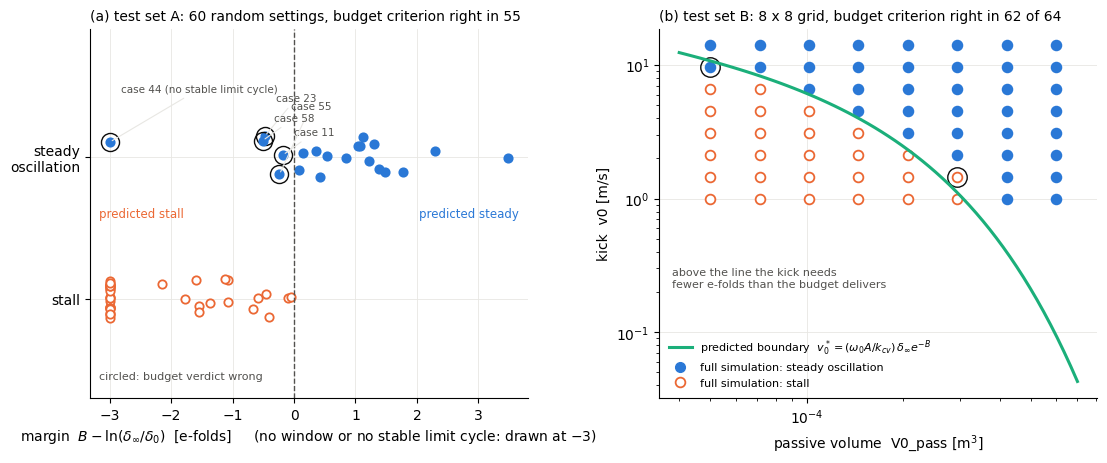

largest |margin| among wrongly classified cases that have a margin: 0.51 e-folds
cases within 0.1 e-folds of the line: 4 of 124, of which right: 4
cases with |margin| > 0.2 e-folds: 88, of which right: 84


In [5]:
ccol = {'steady': BLUE, 'stall': ORANGE}
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8)); fig.subplots_adjust(wspace=0.3)

# (a) test set A: the margin B - need against the outcome of the full simulation
ax = axs[0]; rng2 = np.random.default_rng(1)
for r in dfA.itertuples():
    y = (1.0 if r.truth == 'steady' else 0.0) + rng2.uniform(-0.15, 0.15)
    x = r.margin if np.isfinite(r.margin) else -3.0
    ax.plot(x, y, 'o', color=ccol[r.truth], ms=6, mfc=ccol[r.truth] if r.truth == 'steady' else 'white', mew=1.3)
    if r.pred_B != r.truth:
        ax.plot(x, y, 'o', ms=13, mfc='none', mec=INK, mew=1.0)
        why = ' (no window)' if r.no_window else (' (no stable limit cycle)' if not np.isfinite(r.delta_inf_mbar) else '')
        k = int((dfA.pred_B != dfA.truth)[:r.Index].sum())
        ax.annotate('case %d%s' % (r.case, why), (x, y), xytext=(8, 14 + 11 * (k % 4)) if r.truth == 'steady' else (8, -14 - 11 * (k % 4)),
                    textcoords='offset points', fontsize=7.5, color=INK2, arrowprops=dict(arrowstyle='-', color=GRID, lw=0.8))
ax.axvline(0, color=INK2, lw=1, ls='--')
ax.set_yticks([0, 1]); ax.set_yticklabels(['stall', 'steady\noscillation']); ax.set_ylim(-0.7, 1.9)
ax.set_xlabel(r'margin  $B - \ln(\delta_\infty/\delta_0)$  [e-folds]     (no window or no stable limit cycle: drawn at $-3$)')
ax.set_title('(a) test set A: %d random settings, budget criterion right in %d' % (len(dfA), score(dfA, 'pred_B')[0]), fontsize=10, loc='left')
ax.text(0.02, 0.5, 'predicted stall', transform=ax.transAxes, fontsize=8.5, color=ORANGE, va='center')
ax.text(0.98, 0.5, 'predicted steady', transform=ax.transAxes, fontsize=8.5, color=BLUE, va='center', ha='right')
ax.text(0.02, 0.05, 'circled: budget verdict wrong', transform=ax.transAxes, fontsize=8, color=INK2)

# (b) test set B: the (V0_pass, v0) plane, simulated outcome as markers, predicted boundary as the line
ax = axs[1]
for r in dfB.itertuples():
    ax.plot(r.V0_pass, r.v0, 'o', color=ccol[r.truth], ms=7, mfc=ccol[r.truth] if r.truth == 'steady' else 'white', mew=1.3)
    if r.pred_B != r.truth:
        ax.plot(r.V0_pass, r.v0, 'o', ms=14, mfc='none', mec=INK, mew=1.0)
ax.plot(VPf, v0_star, '-', color=AQUA, lw=2.2, label='predicted boundary  $v_0^* = (\\omega_0 A / k_{cv})\\,\\delta_\\infty e^{-B}$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('passive volume  V0_pass [m$^3$]'); ax.set_ylabel('kick  v0 [m/s]')
ax.set_title('(b) test set B: 8 x 8 grid, budget criterion right in %d of %d' % (score(dfB, 'pred_B')[0], len(dfB)), fontsize=10, loc='left')
ax.plot([], [], 'o', color=BLUE, ms=7, label='full simulation: steady oscillation')
ax.plot([], [], 'o', color=ORANGE, ms=7, mfc='white', mew=1.3, label='full simulation: stall')
ax.legend(frameon=False, fontsize=8, loc='lower left')
ax.text(0.03, 0.30, 'above the line the kick needs\nfewer e-folds than the budget delivers', transform=ax.transAxes, fontsize=8, color=INK2)
for a in axs:
    for sp in ['top', 'right']: a.spines[sp].set_visible(False)
    a.grid(color=GRID, lw=0.6, which='major')
plt.show()

# how sharp is the boundary?  the margins of the wrongly classified cases, and the smallest margins that were classified right
allx = pd.concat([dfA.assign(set='A'), dfB.assign(set='B')], ignore_index=True)
wrong = allx[(allx.pred_B != allx.truth) & allx.margin.notna()]
print('largest |margin| among wrongly classified cases that have a margin: %.2f e-folds' % (wrong.margin.abs().max() if len(wrong) else 0.0))
print('cases within 0.1 e-folds of the line: %d of %d, of which right: %d' % (((allx.margin.abs() < 0.1)).sum(), len(allx), ((allx.margin.abs() < 0.1) & (allx.pred_B == allx.truth)).sum()))
print('cases with |margin| > 0.2 e-folds: %d, of which right: %d' % ((allx.margin.abs() > 0.2).sum(), ((allx.margin.abs() > 0.2) & (allx.pred_B == allx.truth)).sum()))

## 4. What this says

**As a predictor, yes.** From the initial state alone — no oscillation simulated, one root search for the steady amplitude and one quadrature for the drift time — the budget criterion reproduces the outcome of the full simulation in 117 of 124 settings it had never seen (94 percent). The sign of the initial growth rate, the obvious alternative, manages 72 (58 percent), and every one of its 52 misses is the same mistake: a kick that grows at first and dies later. The three slow ODEs integrated in time, of which the budget is a closed-form shortcut, reach 121 (98 percent); the budget gives up 4 settings for the convenience of a formula.

**Where it fails, and why.** With the steady amplitude taken from the stable fixed point, the budget never called a stalling random setting steady. Its five misses in set A are all false stalls. Four of them sit within half an e-fold of the line (margins $-0.18$ to $-0.51$) and share one feature: $\zeta \geq 0.71$ with a reed shut or within a few percent of shutting at the mean pressure ($u_{in} = 1.02$, $1.09$, $1.13$; $u_{out} = 0.81$). There the small-signal $\lambda_{lin}$ underestimates the drive, because the kick's own swing opens the reed for part of each cycle and keeps it driving past the point where the small-signal window closes — the mild form of the $\zeta = 1.2$ failure, where no window exists at all. The fifth (case 44: $\dot m_{max} = 0.32$ g/s, $\zeta = 0.88$, a 207 mbar swing against $\Delta P_{max} = 0.34$ bar) is a limitation of the slow equations themselves, which have no stable fixed point there and are also wrong about it. On the grid, the two misses sit right at the predicted curve (margins $-0.11$ and $+0.27$), and the second is missed by the slow ODEs as well. Of the 124 settings, 4 lie within 0.1 e-folds of the line and all 4 were called right, so the boundary is not fuzzy in a random way; the errors are systematic and confined to the near-shut-reed regime.

**Two versions of the need.** Taking $\delta_\infty$ from the stable fixed point of the slow equations (predictor 3) and simply fixing it at the baseline's 0.295 bar (predictor 2) score the same on these sets (55 and 62), but they fail differently: the fixed value produces confident false steady verdicts when the true steady amplitude is larger than 0.295 bar, the fixed point never did. The fixed-point version is the one to use; its extra cost is a root search of a few milliseconds.

**What the check does not cover.** All settings share the baseline geometry of the cavity ($V_{0c} = 10^{-4}$ m$^3$, neck area, $P_{out}$, $P_0$) and the flow law; the random box spans a factor 10 in valve capacity, 15 in damping, 9 in passive volume, 6 in piston mass, 12 in kick and 0.4 bar in inlet pressure. Outside that box, in particular for reeds that are shut at the mean pressure, the small-signal budget should be replaced by $\lambda$ evaluated at the kick amplitude — that variant is not tested here.